# Home Care Operations in Ireland

## 1. Data Source

**Institution:** Health Service Executive (HSE)

**Documents:** Parliamentary Questions PQ 15085/26 and PQ 15086/26

**Publication date:** 6 March 2026

**Analysis period:** January–December 2025

**Main information:**
- People waiting for new Home Support packages.
- People waiting for additional Home Support hours.
- Direct and indirect Home Support hours delivered.

## 2. Analysis Objective

Investigate changes in Home Support waiting lists and service delivery in Ireland during 2025, comparing the number of people waiting for support with the hours of service delivered.

## 3. Understanding the Waiting List Categories

The HSE document separates people waiting for Home Support into two categories:

- **Carers – New:** People waiting for a new Home Support package.
- **Carers – Additional:** People who already receive Home Support but are waiting for additional service hours.

These categories represent different situations and will be analysed separately to avoid mixing new demand with requests for additional support.

## 4. Geographic Breakdown

The HSE report provides waiting list information for six health regions:

- Dublin North East
- Dublin Midlands
- Dublin South East
- South West
- Mid West
- West and North West

The report also provides a National Total, allowing comparisons between regional figures and the overall national waiting list.

The regional breakdown is available for both Carers – New and Carers – Additional.

However, the hours delivered in Appendix 2 are reported only at national level.

## 5. Analytical Decision — Keeping Waiting List Categories Separate

I decided to analyse Carers – New and Carers – Additional separately because they represent different situations.

Carers – New refers to people waiting for a new Home Support package, while Carers – Additional refers to people already receiving support who are waiting for additional hours.

Combining these categories too early could hide important differences between the two types of waiting lists.

I will therefore analyse each category separately before calculating the combined waiting list, where appropriate.

In [1]:
import pdfplumber
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data_path = Path("../data/raw")

pdf_files = list(data_path.glob("*.pdf"))

for file in pdf_files:
    print(file.name)

PQ_15085-26_-_Pádraig_Rice (1).pdf


In [3]:
pdf_path = pdf_files[0]

with pdfplumber.open(pdf_path) as pdf:
    print('Pages total: ', len(pdf.pages))

    page = pdf.pages[2]
    print(page.extract_text())

Pages total:  3
Appendix 1 : The number of Service Users waiting on carers for both new and additional service delivery broken down by National/RHA area, by
month for 2025
Carers - New
Health Region Jan-25 Feb-25 Mar-25 Apr-25 May-25 Jun-25 Jul-25 Aug-25 Sept-25 Oct-25 Nov-25 Dec-25
National Total 2 ,104 2 ,318 2 ,162 2 ,113 2 ,198 2 ,121 2 ,112 2 ,301 2 ,231 2 ,222 2 ,126 2 ,253
HSE Dublin North East 9 4 2 63 2 34 2 48 2 33 3 12 3 09 4 33 4 36 4 17 3 35 3 50
HSE Dublin Midlands 3 04 4 10 3 58 3 24 3 09 1 20 9 7 1 17 1 30 1 48 1 57 1 13
HSE Dublin South East 3 03 2 57 2 29 2 39 2 38 2 35 2 73 2 90 3 10 3 30 3 61 3 84
HSE South West 5 58 5 63 5 38 5 59 5 64 6 00 5 94 6 07 5 46 5 79 5 52 5 75
HSE Mid West 2 21 2 07 2 02 1 74 1 97 1 81 1 87 2 02 2 56 2 65 2 25 2 45
HSE West and North West 6 24 6 18 6 01 5 69 6 57 6 73 6 52 6 52 5 53 4 83 4 96 5 86
Carers - Additional
Health Region Jan-25 Feb-25 Mar-25 Apr-25 May-25 Jun-25 Jul-25 Aug-25 Sept-25 Oct-25 Nov-25 Dec-25
National Total 2 ,701 2 

In [4]:
tables = page.extract_tables()

print('Found tables among: ', len(tables))

Found tables among:  4


In [5]:
tables[0]

[['Carers - New',
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None],
 ['Health Region Jan-25 Feb-25 Mar-25 Apr-25 May-25 Jun-25 Jul-25 Aug-25 Sept-25 Oct-25 Nov-25 Dec-25',
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  ''],
 ['National Total',
  '2 ,104',
  '2 ,318',
  '2 ,162',
  '2 ,113',
  '2 ,198',
  '2 ,121',
  '2 ,112',
  '2 ,301',
  '2 ,231',
  '2 ,222',
  '2 ,126',
  '2 ,253',
  ''],
 ['HSE Dublin North East',
  '9 4',
  '2 63',
  '2 34',
  '2 48',
  '2 33',
  '3 12',
  '3 09',
  '4 33',
  '4 36',
  '4 17',
  '3 35',
  '3 50',
  None],
 ['HSE Dublin Midlands',
  '3 04',
  '4 10',
  '3 58',
  '3 24',
  '3 09',
  '1 20',
  '9 7',
  '1 17',
  '1 30',
  '1 48',
  '1 57',
  '1 13',
  None],
 ['HSE Dublin South East',
  '3 03',
  '2 57',
  '2 29',
  '2 39',
  '2 38',
  '2 35',
  '2 73',
  '2 90',
  '3 10',
  '3 30',
  '3 61',
  '3 84',
  None],
 ['HSE South West',
  '5 58',
  '5 

In [6]:
for i, table in enumerate(tables):
    print(f"\nTable {i}:")
    print("Rows:", len(table))
    print("Columns:", len(table[0]))
    print("First 3 rows:", table[:3])


Table 0:
Rows: 9
Columns: 14
First 3 rows: [['Carers - New', None, None, None, None, None, None, None, None, None, None, None, None, None], ['Health Region Jan-25 Feb-25 Mar-25 Apr-25 May-25 Jun-25 Jul-25 Aug-25 Sept-25 Oct-25 Nov-25 Dec-25', None, None, None, None, None, None, None, None, None, None, None, None, ''], ['National Total', '2 ,104', '2 ,318', '2 ,162', '2 ,113', '2 ,198', '2 ,121', '2 ,112', '2 ,301', '2 ,231', '2 ,222', '2 ,126', '2 ,253', '']]

Table 1:
Rows: 9
Columns: 14
First 3 rows: [['Carers - Additional', None, None, None, None, None, None, None, None, None, None, None, None, None], ['Health Region Jan-25 Feb-25 Mar-25 Apr-25 May-25 Jun-25 Jul-25 Aug-25 Sept-25 Oct-25 Nov-25 Dec-25', None, None, None, None, None, None, None, None, None, None, None, None, ''], ['National Total', '2 ,701', '2 ,780', '2 ,693', '2 ,742', '2 ,635', '2 ,824', '2 ,931', '3 ,087', '3 ,169', '3 ,155', '3 ,274', '3 ,347', '']]

Table 2:
Rows: 3
Columns: 13
First 3 rows: [['Home Support Act

In [7]:
tables[0][3]

['HSE Dublin North East',
 '9 4',
 '2 63',
 '2 34',
 '2 48',
 '2 33',
 '3 12',
 '3 09',
 '4 33',
 '4 36',
 '4 17',
 '3 35',
 '3 50',
 None]

In [8]:
tables[0][2]

['National Total',
 '2 ,104',
 '2 ,318',
 '2 ,162',
 '2 ,113',
 '2 ,198',
 '2 ,121',
 '2 ,112',
 '2 ,301',
 '2 ,231',
 '2 ,222',
 '2 ,126',
 '2 ,253',
 '']

In [9]:
value = '2 ,104'

clean_value = value.replace(' ', '').replace(',', '')

print(clean_value)

2104


In [10]:
new_table = [row.copy() for row in tables[0]]

new_table[3]

['HSE Dublin North East',
 '9 4',
 '2 63',
 '2 34',
 '2 48',
 '2 33',
 '3 12',
 '3 09',
 '4 33',
 '4 36',
 '4 17',
 '3 35',
 '3 50',
 None]

In [11]:
for row in new_table[2:]:
    for i in range(1, len(row)):
        if row[i] is not None and row[i] != '':
            row[i] = row[i].replace(' ', '').replace(',', '')

new_table[2:4]

[['National Total',
  '2104',
  '2318',
  '2162',
  '2113',
  '2198',
  '2121',
  '2112',
  '2301',
  '2231',
  '2222',
  '2126',
  '2253',
  ''],
 ['HSE Dublin North East',
  '94',
  '263',
  '234',
  '248',
  '233',
  '312',
  '309',
  '433',
  '436',
  '417',
  '335',
  '350',
  None]]

In [12]:
new_table = [row[:-1] for row in new_table]

print("Columns:", len(new_table[0]))
print(new_table[2:4])

Columns: 13
[['National Total', '2104', '2318', '2162', '2113', '2198', '2121', '2112', '2301', '2231', '2222', '2126', '2253'], ['HSE Dublin North East', '94', '263', '234', '248', '233', '312', '309', '433', '436', '417', '335', '350']]


In [13]:
columns = [
    'health_region',
    'jan_2025', 'feb_2025', 'mar_2025', 'apr_2025',
    'may_2025', 'jun_2025', 'jul_2025', 'aug_2025',
    'sep_2025', 'oct_2025', 'nov_2025', 'dec_2025'
]

len(columns)

13

In [14]:
df_carers_new = pd.DataFrame(
    new_table[2:],
    columns=columns
)

df_carers_new.head()

,health_region,jan_2025,feb_2025,mar_2025,apr_2025,may_2025,jun_2025,jul_2025,aug_2025,sep_2025,oct_2025,nov_2025,dec_2025
0,National Total,2104,2318,2162,2113,2198,2121,2112,2301,2231,2222,2126,2253
1,HSE Dublin North East,94,263,234,248,233,312,309,433,436,417,335,350
2,HSE Dublin Midlands,304,410,358,324,309,120,97,117,130,148,157,113
3,HSE Dublin South East,303,257,229,239,238,235,273,290,310,330,361,384
4,HSE South West,558,563,538,559,564,600,594,607,546,579,552,575


In [15]:
df_carers_new.dtypes

health_region    str
jan_2025         str
feb_2025         str
mar_2025         str
apr_2025         str
may_2025         str
jun_2025         str
jul_2025         str
aug_2025         str
sep_2025         str
oct_2025         str
nov_2025         str
dec_2025         str
dtype: object

In [16]:
month_columns = columns[1:]

df_carers_new[month_columns] = df_carers_new[month_columns].astype(int)

df_carers_new.dtypes

health_region      str
jan_2025         int64
feb_2025         int64
mar_2025         int64
apr_2025         int64
may_2025         int64
jun_2025         int64
jul_2025         int64
aug_2025         int64
sep_2025         int64
oct_2025         int64
nov_2025         int64
dec_2025         int64
dtype: object

## Data Extraction and Preparation

The HSE report was provided in PDF format, so I used the `pdfplumber` library to extract the tables from the third page. Four tables were identified, covering people waiting for new Home Support packages, people waiting for additional hours, and direct and indirect Home Support hours delivered.

I started with the *Carers – New* table. First, I created a copy of the extracted data to preserve the original version. Then, I cleaned the numeric values by removing unnecessary spaces and commas, removed an extra empty column generated during the extraction process, and replaced the original headers with standardised column names using `snake_case`.

After cleaning the data, I created a Pandas DataFrame named `df_carers_new` and converted the monthly columns from strings to integers. The resulting dataset contains the national total and six HSE health regions, with monthly waiting list figures from January to December 2025.

Finally, I validated the extracted data by comparing the sum of the six regional values with the reported national total for each month. No differences were found, confirming that the regional figures matched the national totals.

In [17]:
df_regions = df_carers_new[
    df_carers_new['health_region'] != 'National Total'
]

regional_totals = df_regions[month_columns].sum()

regional_totals

jan_2025    2104
feb_2025    2318
mar_2025    2162
apr_2025    2113
may_2025    2198
jun_2025    2121
jul_2025    2112
aug_2025    2301
sep_2025    2231
oct_2025    2222
nov_2025    2126
dec_2025    2253
dtype: int64

In [18]:
national_total = df_carers_new.loc[
    df_carers_new['health_region'] == 'National Total',
    month_columns
].iloc[0]

difference = national_total - regional_totals

difference

jan_2025    0
feb_2025    0
mar_2025    0
apr_2025    0
may_2025    0
jun_2025    0
jul_2025    0
aug_2025    0
sep_2025    0
oct_2025    0
nov_2025    0
dec_2025    0
dtype: int64

The regional data was validated by comparing the sum of the six HSE health regions with the reported national total for each month. The results showed that both figures matched across all 12 months, with no discrepancies identified. This confirms that the regional data extracted from the HSE report is consistent with the reported national totals.

In [19]:
additional_table = [row.copy() for row in tables[1]]

for row in additional_table[2:]:
    for i in range(1, len(row)):
        if row[i] is not None and row[i] != '':
            row[i] = row[i].replace(' ', '').replace(',', '')

additional_table = [row[:-1] for row in additional_table]

additional_table[2:4]

[['National Total',
  '2701',
  '2780',
  '2693',
  '2742',
  '2635',
  '2824',
  '2931',
  '3087',
  '3169',
  '3155',
  '3274',
  '3347'],
 ['HSE Dublin North East',
  '189',
  '463',
  '438',
  '443',
  '367',
  '450',
  '460',
  '576',
  '517',
  '514',
  '492',
  '498']]

In [20]:
df_carers_additional = pd.DataFrame(
    additional_table[2:],
    columns=columns
)

df_carers_additional[month_columns] = (
    df_carers_additional[month_columns].astype(int)
)

df_carers_additional.head()

,health_region,jan_2025,feb_2025,mar_2025,apr_2025,may_2025,jun_2025,jul_2025,aug_2025,sep_2025,oct_2025,nov_2025,dec_2025
0,National Total,2701,2780,2693,2742,2635,2824,2931,3087,3169,3155,3274,3347
1,HSE Dublin North East,189,463,438,443,367,450,460,576,517,514,492,498
2,HSE Dublin Midlands,82,46,146,125,138,165,178,212,216,238,236,245
3,HSE Dublin South East,628,509,473,549,541,547,560,595,699,638,705,727
4,HSE South West,390,373,379,381,369,390,414,438,433,433,425,450


In [21]:
df_additional_regions = df_carers_additional[
    df_carers_additional['health_region'] != 'National Total'
]

additional_regional_totals = df_additional_regions[month_columns].sum()

additional_regional_totals

jan_2025    2701
feb_2025    2780
mar_2025    2693
apr_2025    2742
may_2025    2635
jun_2025    2824
jul_2025    2931
aug_2025    3087
sep_2025    3169
oct_2025    3155
nov_2025    3274
dec_2025    3347
dtype: int64

In [22]:
additional_national_total = df_carers_additional.loc[
    df_carers_additional['health_region'] == 'National Total',
    month_columns
].iloc[0]

additional_difference = (
    additional_national_total - additional_regional_totals
)

additional_difference

jan_2025    0
feb_2025    0
mar_2025    0
apr_2025    0
may_2025    0
jun_2025    0
jul_2025    0
aug_2025    0
sep_2025    0
oct_2025    0
nov_2025    0
dec_2025    0
dtype: int64

The same validation process was applied to the *Carers – Additional* dataset. The sum of the six HSE health regions was compared with the reported national total for each month in 2025. The results matched across all 12 months, with no discrepancies identified. This confirms that the extracted regional data is consistent with the national figures reported by the HSE.

## Analysis of Home Care Waiting Lists

After extracting, cleaning and validating both datasets, the next step is to analyse how the Home Support waiting lists changed throughout 2025.

The two categories will be analysed separately because they represent different situations:

- **Carers – New:** people waiting for a new Home Support package.
- **Carers – Additional:** people who already receive Home Support but are waiting for additional service hours.

Analysing these categories separately allows us to identify differences in their trends and percentage changes without mixing two distinct types of demand.

The initial comparison will focus on the national figures for January and December 2025. This will help measure the overall change in each waiting list during the year. After that, we can explore the monthly trends and regional differences.

In [23]:
new_january = df_carers_new.loc[
    df_carers_new['health_region'] == 'National Total',
    'jan_2025'
].iloc[0]

new_december = df_carers_new.loc[
    df_carers_new['health_region'] == 'National Total',
    'dec_2025'
].iloc[0]

print("January:", new_january)
print("December:", new_december)

January: 2104
December: 2253


In [24]:
new_percentage_change = (
    (new_december - new_january) / new_january
) * 100

print(round(new_percentage_change, 2))

7.08


In [25]:
new_january_additional = df_carers_additional.loc[
    df_carers_additional['health_region'] == 'National Total',
    'jan_2025'
].iloc[0]

new_december_additional = df_carers_additional.loc[
    df_carers_additional['health_region'] == 'National Total',
    'dec_2025'
].iloc[0]

print("January:", new_january_additional)
print("December:", new_december_additional)

January: 2701
December: 3347


In [26]:
new_percentage_change_additional = (
    (new_december_additional - new_january_additional) / new_january_additional
) * 100

print(round(new_percentage_change_additional, 2))

23.92


In [27]:
df_waiting_lists = pd.DataFrame({
    'month': month_columns,
    'carers_new': national_total.values,
    'carers_additional': additional_national_total.values
})

df_waiting_lists

,month,carers_new,carers_additional
0,jan_2025,2104,2701
1,feb_2025,2318,2780
2,mar_2025,2162,2693
3,apr_2025,2113,2742
4,may_2025,2198,2635
5,jun_2025,2121,2824
6,jul_2025,2112,2931
7,aug_2025,2301,3087
8,sep_2025,2231,3169
9,oct_2025,2222,3155


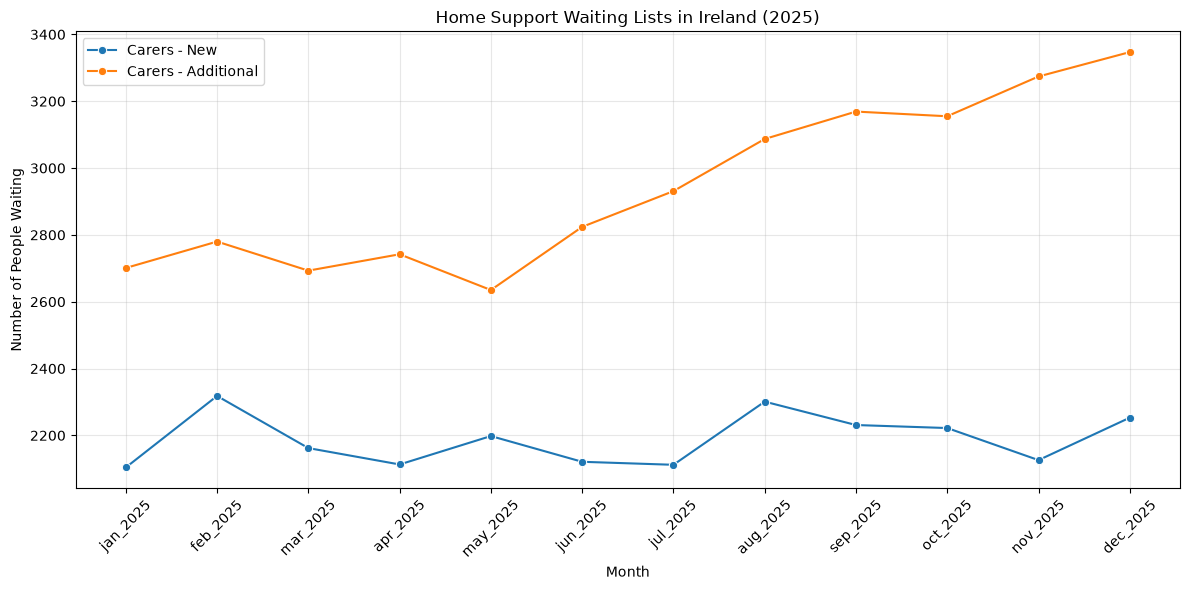

In [28]:
plt.figure(figsize=(12,6))

sns.lineplot(
    data=df_waiting_lists,
    x='month',
    y='carers_new',
    marker='o',
    label='Carers - New'
)

sns.lineplot(
    data=df_waiting_lists,
    x='month',
    y='carers_additional',
    marker='o',
    label='Carers - Additional'
)

plt.title('Home Support Waiting Lists in Ireland (2025)')
plt.xlabel('Month')
plt.ylabel('Number of People Waiting')
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

## Home Care Waiting List Analysis — 2025

The analysis of the HSE waiting list data revealed different patterns between people waiting for new Home Support packages (*Carers – New*) and existing service users waiting for additional hours (*Carers – Additional*).

These categories were analysed separately because they represent different situations and types of demand.

### Carers – New

The number of people waiting for a new Home Support package increased from 2,104 in January to 2,253 in December 2025, representing an increase of 149 people (+7.08%).

Throughout the year, the waiting list showed some fluctuations rather than a consistent upward trend. The highest number was recorded in February, with 2,318 people, while the lowest was recorded in January, with 2,104 people. Another noticeable increase occurred in August, when the total reached 2,301 people.

Despite these monthly variations, the waiting list remained relatively stable compared with the growth observed in the additional hours category.

### Carers – Additional

A more significant increase was observed among existing service users waiting for additional Home Support hours.

The number increased from 2,701 in January to 3,347 in December 2025, representing an increase of 646 people (+23.92%).

The waiting list fluctuated during the first part of the year, reaching its lowest point in May, with 2,635 people. From June onwards, the overall trend was upward, with only a small decrease between September and October. The highest number was recorded in December.

This pattern suggests that requests for additional Home Support hours became a more significant part of the recorded waiting list during the second half of 2025.

### Comparison and Key Findings

The comparison between the two categories highlights an important difference in their development throughout 2025. While *Carers – New* increased by 7.08%, *Carers – Additional* increased by 23.92%.

This difference raises questions about the growing demand for additional support among existing service users. Changes in people's health conditions, levels of independence or care requirements could potentially explain some of this increase. However, the available data does not identify the reasons behind these requests.

It is also important to investigate whether operational capacity, including the availability of care workers and the allocation of additional hours, is sufficient to meet this demand.

### Limitations and Further Investigation

The waiting list figures provide a snapshot of the number of people waiting each month, but they do not show how long each person has been waiting, how many requests were received or completed, or why additional hours were requested.

Therefore, the increase in waiting lists alone cannot determine whether the HSE's operational performance improved or declined.

Further analysis of direct and indirect Home Support hours delivered will help provide additional context about service delivery and its relationship with the recorded waiting lists.

In [29]:
direct_table = [row.copy() for row in tables[2]]

direct_table

[['Home Support Activity - Direct Hours Delivered',
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None],
 ['Health Region Jan-25 Feb-25 Mar-25 Apr-25 May-25 Jun-25 Jul-25 Aug-25 Sept-25 Oct-25 Nov-25 Dec-25',
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None],
 ['National Total',
  '704,385',
  '667,693',
  '682,981',
  '689,806',
  '689,930',
  '692,872',
  '688,878',
  '695,262',
  '681,629',
  '683,283',
  '679,470',
  '668,780']]

In [30]:
direct_data = direct_table[2:]

direct_data

[['National Total',
  '704,385',
  '667,693',
  '682,981',
  '689,806',
  '689,930',
  '692,872',
  '688,878',
  '695,262',
  '681,629',
  '683,283',
  '679,470',
  '668,780']]

In [31]:
direct_data = [
    [value.replace(',', '') if isinstance(value, str) else value
    for value in row]
    for row in direct_data
]

df_direct_hours = pd.DataFrame(
    direct_data,
    columns=columns
)

df_direct_hours[month_columns] = (
    df_direct_hours[month_columns].astype(int)
)

df_direct_hours

,health_region,jan_2025,feb_2025,mar_2025,apr_2025,may_2025,jun_2025,jul_2025,aug_2025,sep_2025,oct_2025,nov_2025,dec_2025
0,National Total,704385,667693,682981,689806,689930,692872,688878,695262,681629,683283,679470,668780


In [32]:
df_direct_hours.isnull().sum()

health_region    0
jan_2025         0
feb_2025         0
mar_2025         0
apr_2025         0
may_2025         0
jun_2025         0
jul_2025         0
aug_2025         0
sep_2025         0
oct_2025         0
nov_2025         0
dec_2025         0
dtype: int64

In [33]:
direct_january = df_direct_hours['jan_2025'].iloc[0]
direct_december = df_direct_hours['dec_2025'].iloc[0]

print("January:", direct_january)
print("December:", direct_december)

January: 704385
December: 668780


In [44]:
direct_percentage_change = (
    (direct_december - direct_january) / direct_january
) * 100

print('Direct hours Percentage: ', round(direct_percentage_change, 2))

Direct hours Percentage:  -5.05


In [35]:
tables[3]

[['Home Support Activity - Indirect Hours Delivered',
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None],
 ['Health Region Jan-25 Feb-25 Mar-25 Apr-25 May-25 Jun-25 Jul-25 Aug-25 Sept-25 Oct-25 Nov-25 Dec-25',
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None],
 ['National Total',
  '1,348,182',
  '1,267,450',
  '1,337,344',
  '1,383,606',
  '1,425,702',
  '1,444,385',
  '1,476,354',
  '1,497,422',
  '1,511,906',
  '1,529,782',
  '1,547,096',
  '1,552,597']]

In [36]:
indirect_table = [row.copy() for row in tables[3]]

indirect_table

[['Home Support Activity - Indirect Hours Delivered',
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None],
 ['Health Region Jan-25 Feb-25 Mar-25 Apr-25 May-25 Jun-25 Jul-25 Aug-25 Sept-25 Oct-25 Nov-25 Dec-25',
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None,
  None],
 ['National Total',
  '1,348,182',
  '1,267,450',
  '1,337,344',
  '1,383,606',
  '1,425,702',
  '1,444,385',
  '1,476,354',
  '1,497,422',
  '1,511,906',
  '1,529,782',
  '1,547,096',
  '1,552,597']]

In [37]:
indirect_data = indirect_table[2:]

indirect_data

[['National Total',
  '1,348,182',
  '1,267,450',
  '1,337,344',
  '1,383,606',
  '1,425,702',
  '1,444,385',
  '1,476,354',
  '1,497,422',
  '1,511,906',
  '1,529,782',
  '1,547,096',
  '1,552,597']]

In [38]:
indirect_data = [
    [value.replace(',', '') if isinstance(value, str) else value
    for value in row]
    for row in indirect_data
]

df_indirect_hours = pd.DataFrame(
    indirect_data,
    columns=columns
)

df_indirect_hours[month_columns] = (
    df_indirect_hours[month_columns].astype(int)
)

df_indirect_hours

,health_region,jan_2025,feb_2025,mar_2025,apr_2025,may_2025,jun_2025,jul_2025,aug_2025,sep_2025,oct_2025,nov_2025,dec_2025
0,National Total,1348182,1267450,1337344,1383606,1425702,1444385,1476354,1497422,1511906,1529782,1547096,1552597


In [39]:
df_indirect_hours.isnull().sum()

health_region    0
jan_2025         0
feb_2025         0
mar_2025         0
apr_2025         0
may_2025         0
jun_2025         0
jul_2025         0
aug_2025         0
sep_2025         0
oct_2025         0
nov_2025         0
dec_2025         0
dtype: int64

In [40]:
indirect_january = df_indirect_hours['jan_2025'].iloc[0]
indirect_december = df_indirect_hours['dec_2025'].iloc[0]

print("Indirect January:", indirect_january)
print("Indirect December:", indirect_december)

Indirect January: 1348182
Indirect December: 1552597


In [43]:
indirect_percentage_change = (
    (indirect_december - indirect_january) / indirect_january
) * 100

print('Indirect hours Percentage: ', round(indirect_percentage_change, 2))

Indirect hours Percentage:  15.16


## Home Support Hours Delivered — Data Preparation

The HSE report also provides monthly figures for Direct and Indirect Home Support Hours Delivered at national level. Unlike the waiting list data, these figures are not broken down by health region.

I extracted both tables using `pdfplumber` and prepared them separately to preserve the distinction between the two types of service delivery. The original values contained commas as thousand separators, which were removed before converting the monthly columns from strings to integers.

Two Pandas DataFrames were created: `df_direct_hours` and `df_indirect_hours`. Both datasets contain monthly figures from January to December 2025.

The initial data quality checks confirmed that the monthly columns contain integer values and no missing data. These datasets are now ready for further analysis and comparison.

In [46]:
df_hours = pd.DataFrame({
    'month': month_columns,
    'direct_hours': df_direct_hours[month_columns].iloc[0].values,
    'indirect_hours': df_indirect_hours[month_columns].iloc[0].values
})

df_hours

,month,direct_hours,indirect_hours
0,jan_2025,704385,1348182
1,feb_2025,667693,1267450
2,mar_2025,682981,1337344
3,apr_2025,689806,1383606
4,may_2025,689930,1425702
5,jun_2025,692872,1444385
6,jul_2025,688878,1476354
7,aug_2025,695262,1497422
8,sep_2025,681629,1511906
9,oct_2025,683283,1529782


In [47]:
df_hours_long = df_hours.melt(
    id_vars='month',
    var_name='hour_type',
    value_name='hours'
)

df_hours_long.head(6)

,month,hour_type,hours
0,jan_2025,direct_hours,704385
1,feb_2025,direct_hours,667693
2,mar_2025,direct_hours,682981
3,apr_2025,direct_hours,689806
4,may_2025,direct_hours,689930
5,jun_2025,direct_hours,692872


In [48]:
df_hours_long['hour_type'].value_counts()

hour_type
direct_hours      12
indirect_hours    12
Name: count, dtype: int64

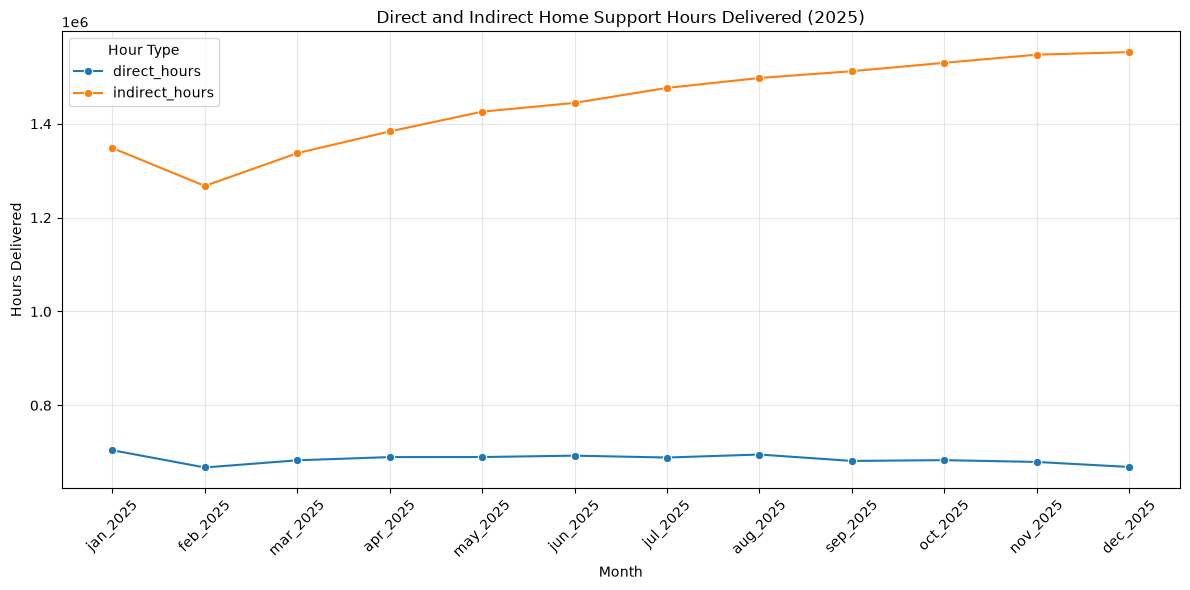

In [49]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_hours_long,
    x='month',
    y='hours',
    hue='hour_type',
    marker='o',
    hue_order=['direct_hours', 'indirect_hours'],
    sort=False
)

plt.title('Direct and Indirect Home Support Hours Delivered (2025)')
plt.xlabel('Month')
plt.ylabel('Hours Delivered')
plt.xticks(rotation=45)
plt.legend(title='Hour Type')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

## Understanding Direct and Indirect Home Support

Before interpreting the monthly hours delivered, it was important to understand the difference between Direct and Indirect Home Support. According to the HSE guidelines, these categories refer to two different service delivery models.

**Direct Home Support** refers to services delivered by care workers directly employed by the HSE. In this model, the HSE employs the staff responsible for providing support to service users in their homes.

**Indirect Home Support** refers to services delivered by external providers, including private companies and not-for-profit organisations, that have formal service arrangements with the HSE. These providers deliver Home Support services on behalf of the HSE.

Both models provide support to people in their own homes. The main difference is who employs and provides the care workers, rather than the type of care delivered.

### Analysis of Direct and Indirect Hours — 2025

The analysis of the HSE data showed different trends between the two service delivery models.

Direct Home Support hours decreased from 704,385 in January to 668,780 in December 2025, representing a reduction of 5.05%.

In contrast, Indirect Home Support hours increased from 1,348,182 to 1,552,597 during the same period, representing an increase of 15.16%.

When both categories are combined, the total number of Home Support hours delivered increased from 2,052,567 in January to 2,221,377 in December, an overall increase of 8.22%.

These results show that external providers accounted for a growing volume of Home Support hours during 2025, while hours delivered directly by HSE employees decreased.

### Key Observation

The increase in Indirect Home Support hours raises questions about the role of external providers in delivering publicly funded Home Support services in Ireland.

It would be useful to investigate whether the HSE increasingly relies on external providers to meet service demand, and whether this change is related to staffing availability, operational capacity or other factors.

However, the available data only shows the volume of hours delivered by each service model. It does not explain the reasons behind these changes or establish whether the shift towards indirect provision improved service capacity or quality.

Further investigation is needed before drawing conclusions about operational performance.

In [50]:
df_hours['total_hours'] = (
    df_hours['direct_hours'] + df_hours['indirect_hours']
)

df_hours

,month,direct_hours,indirect_hours,total_hours
0,jan_2025,704385,1348182,2052567
1,feb_2025,667693,1267450,1935143
2,mar_2025,682981,1337344,2020325
3,apr_2025,689806,1383606,2073412
4,may_2025,689930,1425702,2115632
5,jun_2025,692872,1444385,2137257
6,jul_2025,688878,1476354,2165232
7,aug_2025,695262,1497422,2192684
8,sep_2025,681629,1511906,2193535
9,oct_2025,683283,1529782,2213065


In [51]:
df_home_care = pd.merge(
    df_waiting_lists,
    df_hours,
    on='month',
    how='inner'
)

df_home_care

,month,carers_new,carers_additional,direct_hours,indirect_hours,total_hours
0,jan_2025,2104,2701,704385,1348182,2052567
1,feb_2025,2318,2780,667693,1267450,1935143
2,mar_2025,2162,2693,682981,1337344,2020325
3,apr_2025,2113,2742,689806,1383606,2073412
4,may_2025,2198,2635,689930,1425702,2115632
5,jun_2025,2121,2824,692872,1444385,2137257
6,jul_2025,2112,2931,688878,1476354,2165232
7,aug_2025,2301,3087,695262,1497422,2192684
8,sep_2025,2231,3169,681629,1511906,2193535
9,oct_2025,2222,3155,683283,1529782,2213065


In [53]:
df_home_care_index = df_home_care.copy()

df_home_care_index['total_hours_index'] = (
    df_home_care_index['total_hours'] / df_home_care_index.loc[0, 'total_hours']
) * 100

df_home_care_index

,month,carers_new,carers_additional,direct_hours,indirect_hours,total_hours,total_hours_index
0,jan_2025,2104,2701,704385,1348182,2052567,100.000000
1,feb_2025,2318,2780,667693,1267450,1935143,94.279164
2,mar_2025,2162,2693,682981,1337344,2020325,98.429186
3,apr_2025,2113,2742,689806,1383606,2073412,101.015558
4,may_2025,2198,2635,689930,1425702,2115632,103.072494
5,jun_2025,2121,2824,692872,1444385,2137257,104.126053
6,jul_2025,2112,2931,688878,1476354,2165232,105.488980
7,aug_2025,2301,3087,695262,1497422,2192684,106.826428
8,sep_2025,2231,3169,681629,1511906,2193535,106.867888
9,oct_2025,2222,3155,683283,1529782,2213065,107.819379


In [54]:
df_home_care_index['carers_new_index'] = (
    df_home_care_index['carers_new'] / df_home_care_index.loc[0, 'carers_new']
) * 100

df_home_care_index

,month,carers_new,carers_additional,direct_hours,indirect_hours,total_hours,total_hours_index,carers_new_index
0,jan_2025,2104,2701,704385,1348182,2052567,100.000000,100.000000
1,feb_2025,2318,2780,667693,1267450,1935143,94.279164,110.171103
2,mar_2025,2162,2693,682981,1337344,2020325,98.429186,102.756654
3,apr_2025,2113,2742,689806,1383606,2073412,101.015558,100.427757
4,may_2025,2198,2635,689930,1425702,2115632,103.072494,104.467681
5,jun_2025,2121,2824,692872,1444385,2137257,104.126053,100.807985
6,jul_2025,2112,2931,688878,1476354,2165232,105.488980,100.380228
7,aug_2025,2301,3087,695262,1497422,2192684,106.826428,109.363118
8,sep_2025,2231,3169,681629,1511906,2193535,106.867888,106.036122
9,oct_2025,2222,3155,683283,1529782,2213065,107.819379,105.608365


In [55]:
df_home_care_index['carers_additional_index'] = (
    df_home_care_index['carers_additional'] / df_home_care_index.loc[0, 'carers_additional']
) * 100

df_home_care_index

,month,carers_new,carers_additional,direct_hours,indirect_hours,total_hours,total_hours_index,carers_new_index,carers_additional_index
0,jan_2025,2104,2701,704385,1348182,2052567,100.000000,100.000000,100.000000
1,feb_2025,2318,2780,667693,1267450,1935143,94.279164,110.171103,102.924843
2,mar_2025,2162,2693,682981,1337344,2020325,98.429186,102.756654,99.703813
3,apr_2025,2113,2742,689806,1383606,2073412,101.015558,100.427757,101.517956
4,may_2025,2198,2635,689930,1425702,2115632,103.072494,104.467681,97.556461
5,jun_2025,2121,2824,692872,1444385,2137257,104.126053,100.807985,104.553869
6,jul_2025,2112,2931,688878,1476354,2165232,105.488980,100.380228,108.515365
7,aug_2025,2301,3087,695262,1497422,2192684,106.826428,109.363118,114.291003
8,sep_2025,2231,3169,681629,1511906,2193535,106.867888,106.036122,117.326916
9,oct_2025,2222,3155,683283,1529782,2213065,107.819379,105.608365,116.808589


In [56]:
df_home_care_plot = df_home_care_index[
     ['month', 'total_hours_index', 'carers_new_index', 'carers_additional_index']
].melt(
    id_vars='month',
    var_name='indicator',
    value_name='index'
)

df_home_care_plot.head()

,month,indicator,index
0,jan_2025,total_hours_index,100.000000
1,feb_2025,total_hours_index,94.279164
2,mar_2025,total_hours_index,98.429186
3,apr_2025,total_hours_index,101.015558
4,may_2025,total_hours_index,103.072494


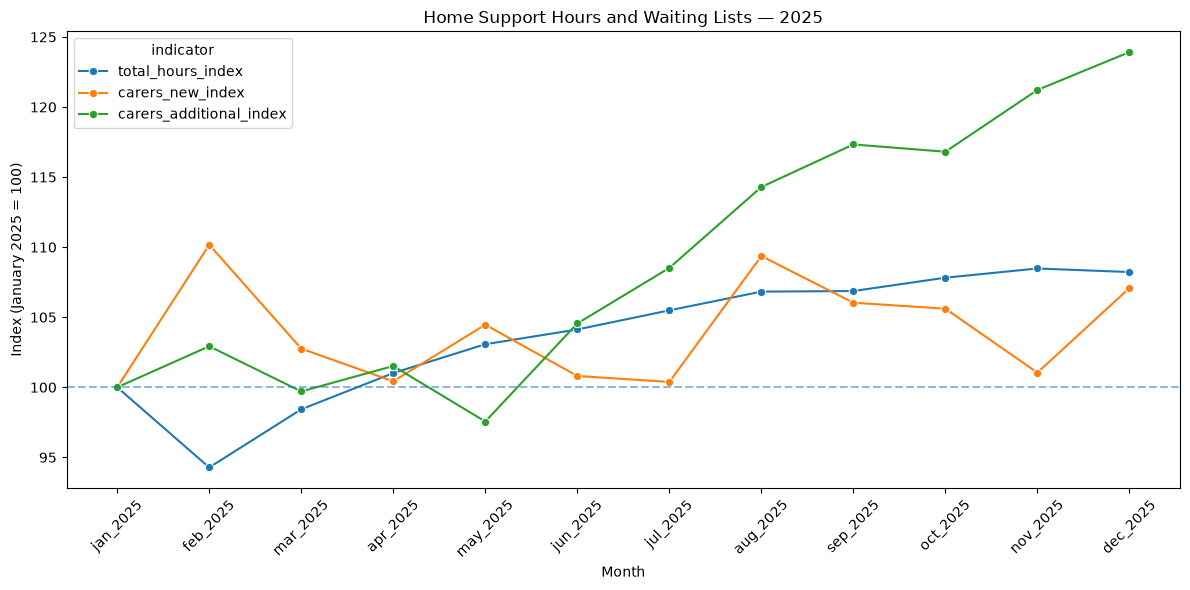

In [57]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_home_care_plot,
    x='month',
    y='index',
    hue='indicator',
    marker='o'
)

plt.axhline(y=100, linestyle='--', alpha=0.5)

plt.title('Home Support Hours and Waiting Lists — 2025')
plt.xlabel('Month')
plt.ylabel('Index (January 2025 = 100)')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Indicator Selection and Rationale

Three indicators were selected to examine the relationship between Home Support service delivery and waiting-list trends in Ireland during 2025.

**Total Home Support Hours Delivered** was selected as an indicator of service delivery, representing the total volume of direct and indirect hours provided through the HSE Home Support system.

**Carers – New** was selected to represent people waiting to access a new Home Support package. This indicator helps assess the pressure associated with providing initial access to the service.

**Carers – Additional** was selected to represent people already receiving Home Support who are waiting for additional hours. This provides a separate perspective on the need for increased support among existing service users.

Together, these indicators allow us to examine service delivery alongside two different types of waiting-list pressure: demand for new support packages and demand for additional hours.

The indicators were also converted into monthly indices, using January 2025 as the baseline (January = 100), to make their relative changes comparable despite their different units of measurement.

These indicators were selected because they provide complementary operational perspectives. However, they do not represent total demand or the full capacity of the Home Support system.

## Comparing Home Support Hours and Waiting Lists — 2025

### Objective

The purpose of this analysis is to compare the monthly evolution of Home Support hours delivered with the number of people waiting for a new Home Support package or additional support hours in Ireland during 2025.

To make the comparison easier, an index was calculated for each indicator, using January 2025 as the baseline (January = 100). This approach allows us to compare relative changes over time, even though the indicators have different units of measurement.

### Key Findings

Between January and December 2025:

- **Total Home Support hours delivered** increased by 8.22%.
- **People waiting for a new Home Support package (Carers – New)** increased by 7.08%.
- **People already receiving support but waiting for additional hours (Carers – Additional)** increased by 23.92%.

The monthly trends show that total hours delivered generally increased throughout the year, although there was a noticeable decrease in February.

The number of people waiting for additional hours showed a stronger upward trend, particularly from June onwards. By December, this indicator had increased by almost 24% compared with January.

### Graph Interpretation

The line chart compares the three indicators using January 2025 as the baseline (100).

The total hours delivered decreased in February, reaching approximately 94.28, before recovering and showing a gradual upward trend during the following months. It reached its highest level in November, at approximately 108.48, followed by a small decrease in December.

The Carers – New waiting list fluctuated throughout the year, with noticeable increases in February and August. Despite these variations, it ended December at 107.08, representing a 7.08% increase compared with January.

The Carers – Additional waiting list showed the strongest upward trend. After some fluctuations during the first half of the year, it increased more consistently from June onwards, reaching 123.92 in December. This represents a 23.92% increase compared with January.

Overall, the graph highlights a difference between the growth in Home Support hours delivered and the growth in the waiting list for additional support hours. While delivered hours increased gradually, the additional waiting list grew at a considerably faster rate.

### Interpretation

The results suggest that the growth in Home Support hours delivered may not have kept pace with the increase in demand for additional support hours.

While total hours delivered increased during 2025, the number of people waiting for additional hours grew at a considerably faster rate. This may indicate increasing pressure on the Home Support system.

The difference between these trends is particularly relevant because people on the Carers – Additional waiting list are already receiving Home Support but are waiting for more hours. This suggests that existing support arrangements may not fully meet the additional hours being requested.

However, the available data does not allow us to determine whether the increase in waiting lists was directly caused by insufficient service capacity.

### Limitations

This analysis is based on aggregated monthly data and does not establish a direct relationship between waiting lists and hours delivered.

The available data does not provide information about individual waiting times, the number of hours requested but not delivered, or the reasons behind changes in waiting lists.

Carers – New and Carers – Additional represent different waiting-list categories. They have therefore been analysed separately, without assuming that they represent entirely different individuals.

### Conclusion

In 2025, Home Support hours delivered increased by 8.22%, while the waiting list for additional support hours increased by 23.92%.

This difference highlights a potential gap between service expansion and growing demand for additional support. Further analysis of regional waiting lists may help identify where these pressures are more pronounced.